# DATA INTENSIVE SYSTEMS IN BIOMEDICINE

## Opis projektu:

Celem niniejszego projektu jest przeprowadzenie kompleksowej analizy inżynierskiej zbioru danych dotyczącego wskaźników zdrowotnych powiązanych z ryzykiem zachorowania na cukrzycę. Projekt został zrealizowany w oparciu o architekturę Apache Spark, co zapewnia wysoką wydajność obliczeniową oraz skalowalność przetwarzania danych.

---
## Wymogi: 
* ``Przeprowadź czyszczenie danych (jesli jest to wymagane lub nie – w obu przypadkach uzasadnij), zweryfikuj ilość pustych wartości i czy mają jakiś wpływ na analizę ``
* ``Przedstaw klasyfikację danych ``
* ``Wykorzystaj MLlib do predykcji ``
* ``Uwzględnij wizualizację danych za pomocą bibliotek pandas lub matplotlib.``
* ``Skorzystaj z paradygmatu MapReduce oraz funkcji lambda. ``
---

## Wczytanie danych za pomocą spark i wyświetlenie 10 pierwszych wierszy

In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Diabetes Analysis") \
    .getOrCreate()

DATA_PATH = "/app/data/diabetes_health_indicators.csv"

df = spark.read.csv(
    DATA_PATH,
    header=True,
    inferSchema=True
)

df.show(10, truncate=False)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/06/15 00:31:14 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


+------------+------+--------+---------+----+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+----+---------+------+
|Diabetes_012|HighBP|HighChol|CholCheck|BMI |Smoker|Stroke|HeartDiseaseorAttack|PhysActivity|Fruits|Veggies|HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth|MentHlth|PhysHlth|DiffWalk|Sex|Age |Education|Income|
+------------+------+--------+---------+----+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+----+---------+------+
|0.0         |1.0   |1.0     |1.0      |40.0|1.0   |0.0   |0.0                 |0.0         |0.0   |1.0    |0.0              |1.0          |0.0        |5.0    |18.0    |15.0    |1.0     |0.0|9.0 |4.0      |3.0   |
|0.0         |0.0   |0.0     |0.0      |25.0|1.0   |0.0   |0.0                 |1.0         |0.0   |0.0    |0.0              |0.0          |1.0 

In [2]:
print("-" * 15 + "Informacje o Strukturze bazy danych" + "-" * 15)
print(f'Całkowita ilość wierszy: {df.count()}')
print(f'Całkowita ilość kolumn: {len(df.columns)}')
print(f'Nazwy kolumn: {df.columns}')
print(65 * "-")

---------------Informacje o Strukturze bazy danych---------------
Całkowita ilość wierszy: 253680
Całkowita ilość kolumn: 22
Nazwy kolumn: ['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
-----------------------------------------------------------------


## Sprawdzenie czy występują puste wiersze

In [3]:
from pyspark.sql.functions import col, count, when

# Zliczanie brakujących (null) wartości w każdej kolumnie
missing_values = df.select([
    count(when(col(c).isNull(), c)).alias(c) 
    for c in df.columns
])

missing_values.show(truncate=False)

+------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+---+---------+------+
|Diabetes_012|HighBP|HighChol|CholCheck|BMI|Smoker|Stroke|HeartDiseaseorAttack|PhysActivity|Fruits|Veggies|HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth|MentHlth|PhysHlth|DiffWalk|Sex|Age|Education|Income|
+------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+---+---------+------+
|0           |0     |0       |0        |0  |0     |0     |0                   |0           |0     |0      |0                |0            |0          |0      |0       |0       |0       |0  |0  |0        |0     |
+------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-

Dla każdej kolumny sprawdzono liczbę wartości NULL. Wyniki pokazują, że:

- żadna kolumna nie zawiera brakujących danych,
- wszystkie wartości wynoszą 0 (brak braków).

W związku z tym zbiór danych nie wymagał procesu czyszczenia. Brak brakujących danych oznacza, że dane są kompletne i mogą zostać bezpośrednio wykorzystane do dalszej analizy oraz budowy modelu ML.

---

## Przedstawienie klasyfikacji danych

In [4]:
df.printSchema()

root
 |-- Diabetes_012: double (nullable = true)
 |-- HighBP: double (nullable = true)
 |-- HighChol: double (nullable = true)
 |-- CholCheck: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Smoker: double (nullable = true)
 |-- Stroke: double (nullable = true)
 |-- HeartDiseaseorAttack: double (nullable = true)
 |-- PhysActivity: double (nullable = true)
 |-- Fruits: double (nullable = true)
 |-- Veggies: double (nullable = true)
 |-- HvyAlcoholConsump: double (nullable = true)
 |-- AnyHealthcare: double (nullable = true)
 |-- NoDocbcCost: double (nullable = true)
 |-- GenHlth: double (nullable = true)
 |-- MentHlth: double (nullable = true)
 |-- PhysHlth: double (nullable = true)
 |-- DiffWalk: double (nullable = true)
 |-- Sex: double (nullable = true)
 |-- Age: double (nullable = true)
 |-- Education: double (nullable = true)
 |-- Income: double (nullable = true)



### Opis struktury danych

Dzięki zastosowaniu funkcji `printSchema()` możliwe jest wyświetlenie struktury analizowanej bazy danych. Analizując wynik funkcji można zauważyć, że:
- wszystkie kolumny w zbiorze danych są typu numerycznego (`double`),
- każda kolumna dopuszcza wartości NULL (nullable = true), jednak wcześniejsza analiza wykazała brak brakujących danych.

In [5]:
df.describe().show(truncate=False)

26/06/15 00:31:23 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-------------------+-------------------+-------------------+------------------+------------------+-------------------+-------------------+--------------------+------------------+-------------------+-------------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+-------------------+------------------+------------------+------------------+------------------+
|summary|Diabetes_012       |HighBP             |HighChol           |CholCheck         |BMI               |Smoker             |Stroke             |HeartDiseaseorAttack|PhysActivity      |Fruits             |Veggies            |HvyAlcoholConsump  |AnyHealthcare      |NoDocbcCost        |GenHlth           |MentHlth          |PhysHlth          |DiffWalk           |Sex               |Age               |Education         |Income            |
+-------+-------------------+-------------------+-------------------+------------------+------------------+-----------

### Podział zmiennych

Na podstawie analizy zbioru danych można wyróżnić kilka typów zmiennych, które się w nim znajdują:

| Typ zmiennej | Nazwa zmiennej | Opis | Wartości / Zakres |
| :--- | :--- | :--- | :--- |
| **Docelowa** | `Diabetes_012` | Status cukrzycy | 0 – brak, 1 – stan przedcukrzycowy, 2 – cukrzyca |
| **Binarna** | `HighBP` | Nadciśnienie | 0 – brak, 1 – występuje |
| **Binarna** | `HighChol` | Wysoki cholesterol | 0 – brak, 1 – występuje |
| **Binarna** | `CholCheck` | Badanie cholesterolu w ciągu ostatnich 5 lat | 0 – brak, 1 – tak |
| **Binarna** | `Smoker` | Czy kiedykolwiek wypalono ≥100 papierosów | 0 – nie, 1 – tak |
| **Binarna** | `Stroke` | Przebyty udar | 0 – nie, 1 – tak |
| **Binarna** | `HeartDiseaseorAttack` | Choroba serca lub zawał | 0 – nie, 1 – tak |
| **Binarna** | `PhysActivity` | Aktywność fizyczna w ostatnich 30 dniach | 0 – brak, 1 – tak |
| **Binarna** | `Fruits` | Spożycie owoców ≥1 raz dziennie | 0 – nie, 1 – tak |
| **Binarna** | `Veggies` | Spożycie warzyw ≥1 raz dziennie | 0 – nie, 1 – tak |
| **Binarna** | `HvyAlcoholConsump` | Nadmierne spożycie alkoholu | 0 – nie, 1 – tak |
| **Binarna** | `AnyHealthcare` | Dostęp do opieki zdrowotnej | 0 – brak, 1 – tak |
| **Binarna** | `NoDocbcCost` | Brak wizyty lekarskiej z powodu kosztów | 0 – nie, 1 – tak |
| **Binarna** | `DiffWalk` | Trudności w chodzeniu lub wchodzeniu po schodach | 0 – brak, 1 – tak |
| **Binarna** | `Sex` | Płeć | 0 – female, 1 – male |
| **Ciągła** | `BMI` | Wskaźnik masy ciała | Zakres: 12 – 98 |
| **Kategoryczna** | `GenHlth` | Ogólny stan zdrowia | 1 (excellent) do 5 (poor) |
| **Kategoryczna** | `MentHlth` | Liczba dni gorszego samopoczucia psychicznego | Zakres: 0 – 30 |
| **Kategoryczna** | `Age` | Kategoria wieku | Skala: 1 – 13 |
| **Kategoryczna** | `PhysHlth` | Liczba dni niezdrowego trybu życia | Zakres: 0 – 30 |
| **Kategoryczna** | `Education` | Poziom edukacji | 1 (brak/przedszkole) do 6 (wyższe) |
| **Kategoryczna** | `Income` | Poziom dochodu | 1 (< $10,000) do 8 (≥ $75,000) |

Dla zmiennych **binarnych i kategorycznych** zastosowano analizę rozkładu wartości. Żeby zapoznać się z rozkładem tego typu danych.

In [6]:
categorical_columns = [c for c in df.columns if c != "BMI"]

total_count = df.count()

for col_name in categorical_columns:
    print(f"\nKolumna: {col_name}")
    
    df.groupBy(col_name) \
      .count() \
      .orderBy(col_name) \
      .show(truncate=False)


Kolumna: Diabetes_012
+------------+------+
|Diabetes_012|count |
+------------+------+
|0.0         |213703|
|1.0         |4631  |
|2.0         |35346 |
+------------+------+


Kolumna: HighBP
+------+------+
|HighBP|count |
+------+------+
|0.0   |144851|
|1.0   |108829|
+------+------+


Kolumna: HighChol
+--------+------+
|HighChol|count |
+--------+------+
|0.0     |146089|
|1.0     |107591|
+--------+------+


Kolumna: CholCheck
+---------+------+
|CholCheck|count |
+---------+------+
|0.0      |9470  |
|1.0      |244210|
+---------+------+


Kolumna: Smoker
+------+------+
|Smoker|count |
+------+------+
|0.0   |141257|
|1.0   |112423|
+------+------+


Kolumna: Stroke
+------+------+
|Stroke|count |
+------+------+
|0.0   |243388|
|1.0   |10292 |
+------+------+


Kolumna: HeartDiseaseorAttack
+--------------------+------+
|HeartDiseaseorAttack|count |
+--------------------+------+
|0.0                 |229787|
|1.0                 |23893 |
+--------------------+------+


Kolu

Po określeniu rozkładu cech nakreślona została macież korelacji aby określic, które czynniki mają największy związek z ryzykiem wystapienia cukrzycy.

Text(0.5, 1.0, 'Macierz korelacji wszystkich cech')

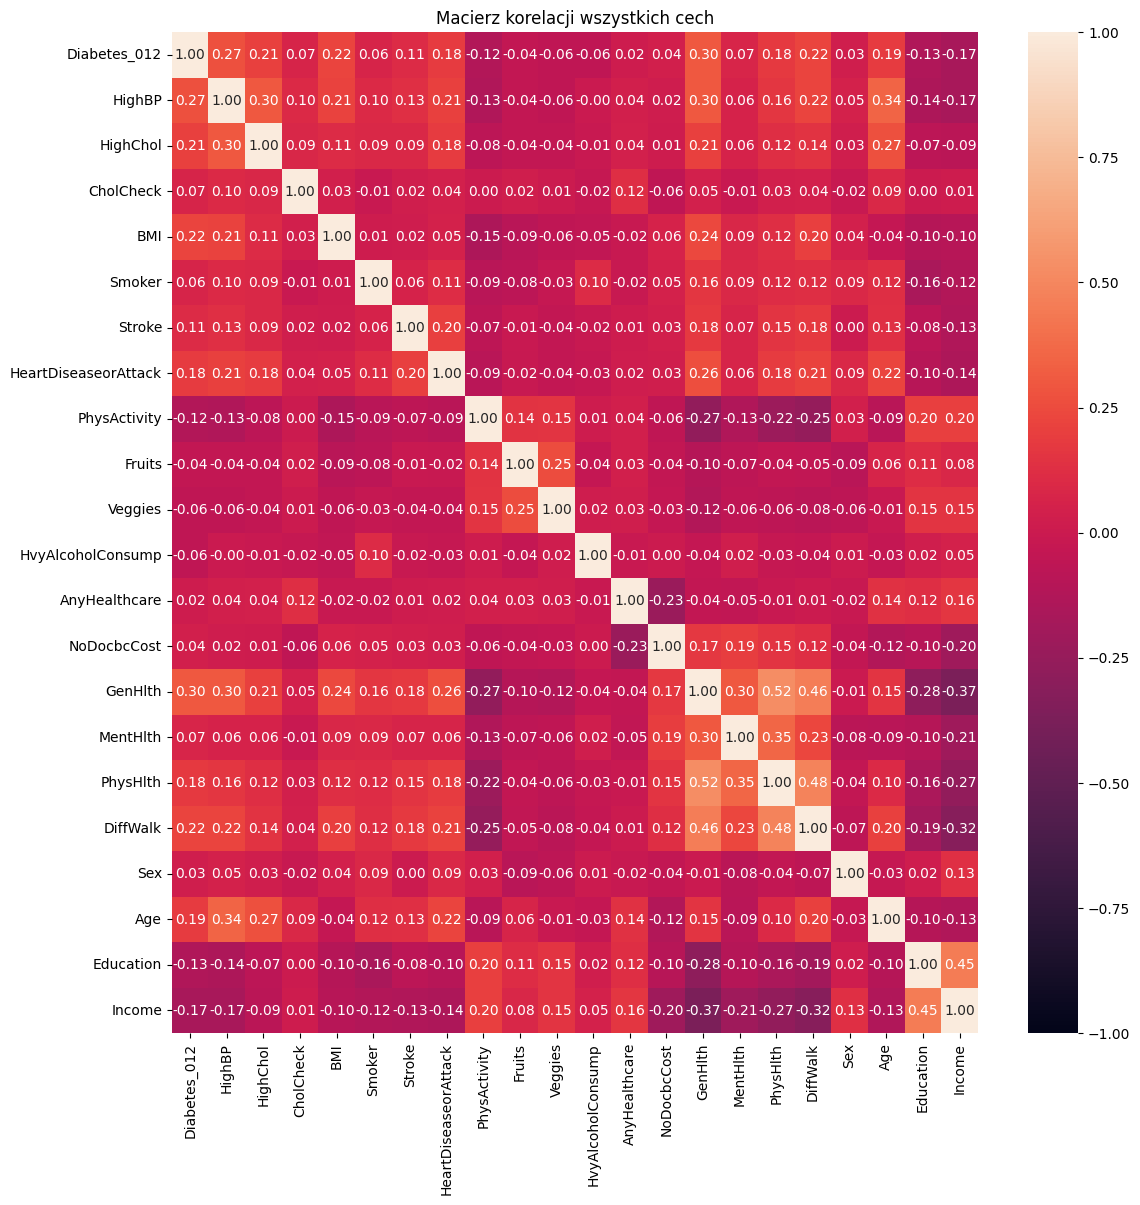

In [14]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

all_cols = df.columns

assembler = VectorAssembler(inputCols=all_cols, outputCol="features")
df_vectorized = assembler.transform(df)

matrix = Correlation.corr(df_vectorized, "features").head()[0]
corr_df = pd.DataFrame(matrix.toArray(), index=all_cols, columns=all_cols)

plt.figure(figsize=(13, 13))
sns.heatmap(corr_df, annot=True, vmin=-1, vmax=1, fmt=".2f")
plt.title("Macierz korelacji wszystkich cech")